In [1]:
# Logistic Regression

In [2]:
# 1. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

In [4]:
# 2. Load dataset

In [5]:
df = pd.read_csv("healthcare_logistic_dataset.csv")

df.head()

,age,bmi,glucose,disease_risk
0,71,25.969811,111.677210,0
1,29,25.664514,101.995071,0
2,62,21.459882,131.359200,0
3,54,17.420806,140.276124,0
4,44,31.155618,110.999420,0


In [6]:
# 3. Explore the dataset

In [7]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["disease_risk"].value_counts())

print("\nTarget Percentage:")
print(df["disease_risk"].value_counts(normalize=True) * 100)

Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           10000 non-null  int64  
 1   bmi           10000 non-null  float64
 2   glucose       10000 non-null  float64
 3   disease_risk  10000 non-null  int64  
dtypes: float64(2), int64(2)
memory usage: 312.6 KB

Statistical Summary:
                age           bmi       glucose  disease_risk
count  10000.000000  10000.000000  10000.000000  10000.000000
mean      49.367000     24.941933    120.027614      0.038900
std       17.287573      4.944332     29.728517      0.193366
min       20.000000      4.134272     -0.003881      0.000000
25%       34.000000     21.575899     99.974726      0.000000
50%       49.000000     24.937132    120.059802      0.000000
75%       64.000000     28.365326    140.167487      0.000000
max       79.0000

In [8]:
# 4. Visualize the dataset

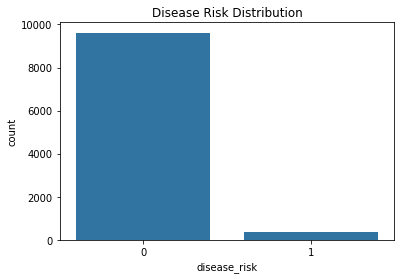

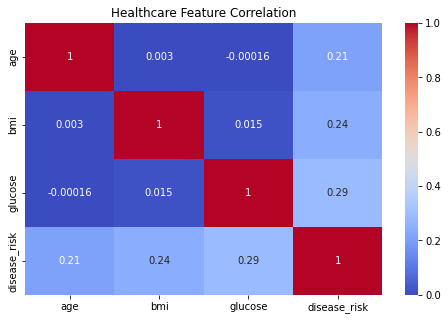

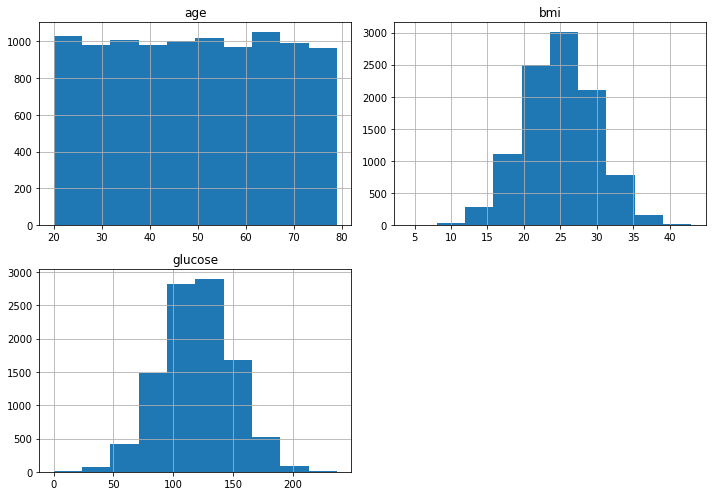

In [9]:
# Disease risk distribution
sns.countplot(data=df, x="disease_risk")
plt.title("Disease Risk Distribution")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Healthcare Feature Correlation")
plt.show()

# Feature distributions
df[["age", "bmi", "glucose"]].hist(figsize=(10, 7))
plt.tight_layout()
plt.show()

In [10]:
# 5. Define independent and dependent variables

In [11]:
X = df[["age", "bmi", "glucose"]]

y = df["disease_risk"]

In [12]:
# 6. Split the dataset

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 3)
Testing Data: (2000, 3)


In [14]:
# 7. Build and train the Logistic Regression model

In [15]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [16]:
# 8. Make predictions

In [17]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Predictions:")
print(y_pred[:10])

Predictions:
[0 0 0 0 0 0 0 0 0 0]


In [18]:
# 9. Evaluate the model

In [19]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, y_pred, zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.9865
Precision: 0.7428571428571429
Recall: 1.0
F1 Score: 0.8524590163934426

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1922
           1       0.74      1.00      0.85        78

    accuracy                           0.99      2000
   macro avg       0.87      0.99      0.92      2000
weighted avg       0.99      0.99      0.99      2000

ROC-AUC: 1.0


In [20]:
# 10. Confusion matrix

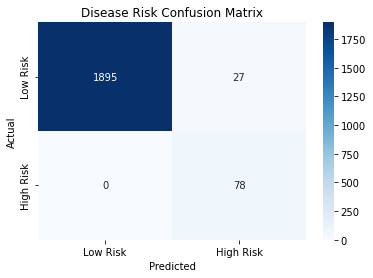

In [21]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Disease Risk Confusion Matrix")
plt.show()

In [22]:
# 11. ROC curve

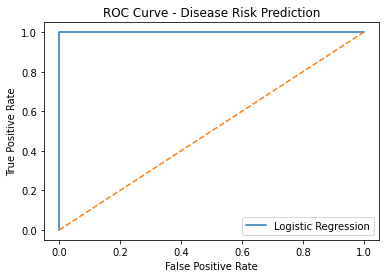

In [23]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Disease Risk Prediction")
plt.legend()
plt.show()

In [24]:
# 12. Predict disease risk for a new patient

In [25]:
new_patient = pd.DataFrame({
    "age": [55],
    "bmi": [30.5],
    "glucose": [160]
})

prediction = model.predict(new_patient)[0]
probability = model.predict_proba(new_patient)[0][1]

if prediction == 1:
    print("Predicted Category: High Risk")
else:
    print("Predicted Category: Low Risk")

print("Predicted Risk Probability:", round(probability * 100, 2), "%")

Predicted Category: High Risk
Predicted Risk Probability: 60.73 %
